In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly. express as px
import warnings
from six.moves import urllib

warnings.filterwarnings("ignore")

%matplotlib inline

In [19]:
import os
import pandas as pd
import urllib.request

download_dir = "./data/"
os.makedirs(download_dir, exist_ok=True)

download_url = "https://raw.githubusercontent.com/ayush700714/Car_Price_Prediction_Cardekho_Dataset/master/car%20data.csv"

filename = "car_data.csv"
download_file_path = os.path.join(download_dir, filename)

urllib.request.urlretrieve(download_url, download_file_path)

print('-' * 100)
print('Data with name ' + filename + ' Downloaded at ' + download_file_path)
print('-' * 100)

df = pd.read_csv(download_file_path)

print(df.head())
print(df.shape)

----------------------------------------------------------------------------------------------------
Data with name car_data.csv Downloaded at ./data/car_data.csv
----------------------------------------------------------------------------------------------------
  Car_Name  Year  Selling_Price  Present_Price  Kms_Driven Fuel_Type  \
0     ritz  2014           3.35           5.59       27000    Petrol   
1      sx4  2013           4.75           9.54       43000    Diesel   
2     ciaz  2017           7.25           9.85        6900    Petrol   
3  wagon r  2011           2.85           4.15        5200    Petrol   
4    swift  2014           4.60           6.87       42450    Diesel   

  Seller_Type Transmission  Owner  
0      Dealer       Manual      0  
1      Dealer       Manual      0  
2      Dealer       Manual      0  
3      Dealer       Manual      0  
4      Dealer       Manual      0  
(301, 9)


In [20]:
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [21]:
print('The size of Dataframe is: ', df. shape)
print('-'*100)
print('The Column Name, Record Count and Data Types are as follows: ')
df.info()
print('-'*100)

The size of Dataframe is:  (301, 9)
----------------------------------------------------------------------------------------------------
The Column Name, Record Count and Data Types are as follows: 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB
----------------------------------------------------------------------------------------------------


In [23]:
# Defining numerical & categorical columns
numeric_features = [feature for feature in df.columns if df[feature].dtype != '0']
categorical_features = [feature for feature in df.columns if df[feature].dtype == '0']

# print columns
print('We have {} numerical features : {}'.format(len(numeric_features), numeric_features))
print('\nWe have {} categorical features : {}'.format(len(categorical_features), categorical_features))

We have 9 numerical features : ['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner']

We have 0 categorical features : []


In [25]:
print('Missing Value Presence in different columns of DataFrame are as follows :')

print('-' * 100)

total = df.isnull().sum().sort_values(ascending=False)
percent =(df.isnull().sum() / df.isnull().count() *
100). sort_values(ascending=False)
pd.concat( [total, percent], axis=1, keys=['Total', 'Percent'])

Missing Value Presence in different columns of DataFrame are as follows :
----------------------------------------------------------------------------------------------------


,Total,Percent
Car_Name,0,0.0
Year,0,0.0
Selling_Price,0,0.0
Present_Price,0,0.0
Kms_Driven,0,0.0
Fuel_Type,0,0.0
Seller_Type,0,0.0
Transmission,0,0.0
Owner,0,0.0


In [27]:
print('Summary Statistics of numerical features for DataFrame are as follows:')
print('-'*100)
df.describe()

Summary Statistics of numerical features for DataFrame are as follows:
----------------------------------------------------------------------------------------------------


,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.644115,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


In [28]:
4.000000e+04, 3.950000e+07

(40000.0, 39500000.0)

In [29]:
print('Summary Statistics of categorical features for DataFrame are as follows:')
print('-'*100)
df.describe(include= 'object')

Summary Statistics of categorical features for DataFrame are as follows:
----------------------------------------------------------------------------------------------------


,Car_Name,Fuel_Type,Seller_Type,Transmission
count,301,301,301,301
unique,98,3,2,2
top,city,Petrol,Dealer,Manual
freq,26,239,195,261


In [31]:
print('-'*125)
print('Checking records for mis-spell, typo-error etc.')
print('-'*125)

print("'Car_Name' variable have {} unique category : \n{}\n".format(
    df['Car_Name'].nunique(),
    df['Car_Name'].unique()
))
print('-'*125)

print("'Seller_Type' variable have {} unique category : \n{}\n".format(
    df['Seller_Type'].nunique(),
    df['Seller_Type'].unique()
))
print('-'*125)

print("'Fuel_Type' variable have {} unique category : \n{}\n".format(
    df['Fuel_Type'].nunique(),
    df['Fuel_Type'].unique()
))
print('-'*125)

print("'Transmission' variable have {} unique category : \n{}\n".format(
    df['Transmission'].nunique(),
    df['Transmission'].unique()
))
print('-'*125)

print("'Owner' variable have {} unique category : \n{}\n".format(
    df['Owner'].nunique(),
    df['Owner'].unique()
))
print('-'*125)

-----------------------------------------------------------------------------------------------------------------------------
Checking records for mis-spell, typo-error etc.
-----------------------------------------------------------------------------------------------------------------------------
'Car_Name' variable have 98 unique category : 
['ritz' 'sx4' 'ciaz' 'wagon r' 'swift' 'vitara brezza' 's cross'
 'alto 800' 'ertiga' 'dzire' 'alto k10' 'ignis' '800' 'baleno' 'omni'
 'fortuner' 'innova' 'corolla altis' 'etios cross' 'etios g' 'etios liva'
 'corolla' 'etios gd' 'camry' 'land cruiser' 'Royal Enfield Thunder 500'
 'UM Renegade Mojave' 'KTM RC200' 'Bajaj Dominar 400'
 'Royal Enfield Classic 350' 'KTM RC390' 'Hyosung GT250R'
 'Royal Enfield Thunder 350' 'KTM 390 Duke ' 'Mahindra Mojo XT300'
 'Bajaj Pulsar RS200' 'Royal Enfield Bullet 350'
 'Royal Enfield Classic 500' 'Bajaj Avenger 220' 'Bajaj Avenger 150'
 'Honda CB Hornet 160R' 'Yamaha FZ S V 2.0' 'Yamaha FZ 16'
 'TVS Apache RT

In [42]:
print('-'*100)
print('The percentage of each category in categorical column are as follow : ')
print('-'*100 + '\n')

for col in categorical_features:
    print(f"\nColumn: {col}")
    print(df[col].value_counts(normalize=True) * 100)
    print('-'*100)

----------------------------------------------------------------------------------------------------
The percentage of each category in categorical column are as follow : 
----------------------------------------------------------------------------------------------------


Column: Car_Name
Car_Name
city                        8.637874
corolla altis               5.315615
verna                       4.651163
fortuner                    3.654485
brio                        3.322259
                              ...   
Honda CB Trigger            0.332226
Yamaha FZ S                 0.332226
Bajaj Pulsar 135 LS         0.332226
Activa 4g                   0.332226
Bajaj Avenger Street 220    0.332226
Name: proportion, Length: 98, dtype: float64
----------------------------------------------------------------------------------------------------

Column: Fuel_Type
Fuel_Type
Petrol    79.401993
Diesel    19.933555
CNG        0.664452
Name: proportion, dtype: float64
------------------------

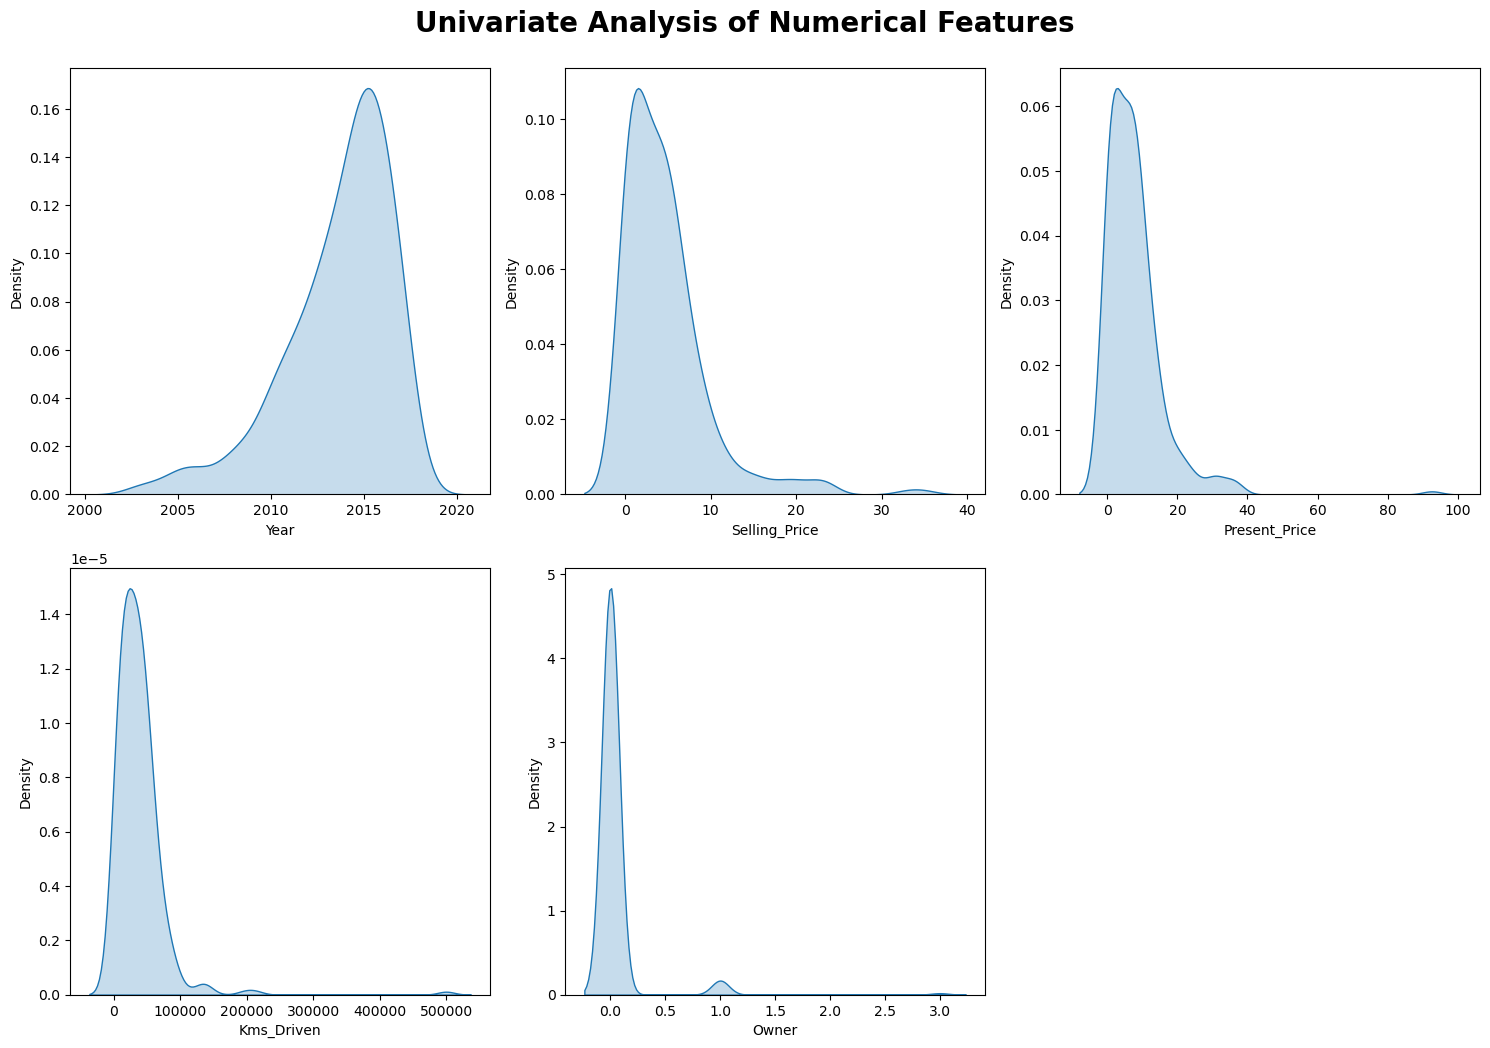

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 15))
plt.suptitle('Univariate Analysis of Numerical Features',
             fontsize=20,
             fontweight='bold',
             y=1.0)

for i in range(len(numeric_features)):
    plt.subplot(3, 3, i + 1)
    sns.kdeplot(data=df, x=numeric_features[i], fill=True)
    plt.xlabel(numeric_features[i])

plt.tight_layout()
plt.show()

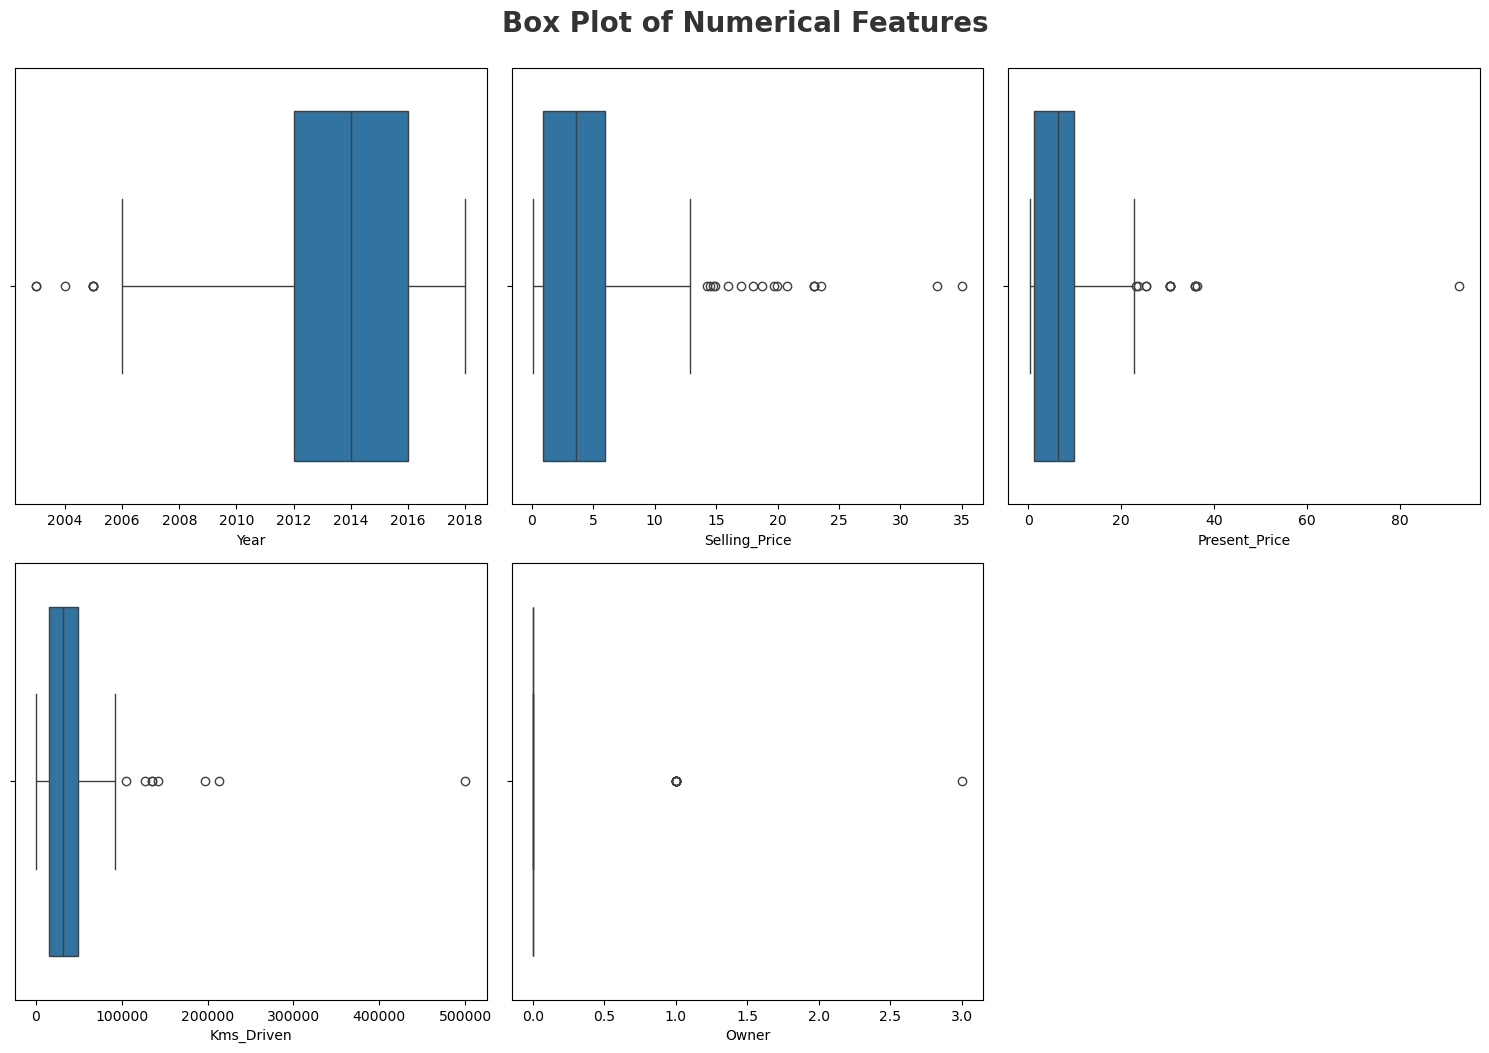

In [48]:
plt.figure(figsize=(15, 15))
plt.suptitle('Box Plot of Numerical Features', fontsize=20, fontweight='bold', alpha=0.8, y=1.0)
for i in range(0, len(numeric_features)):
    plt.subplot(3, 3, i+1)
    sns. boxplot (x=df [numeric_features [i]])
    plt.xlabel(numeric_features [i])
    plt.tight_layout()

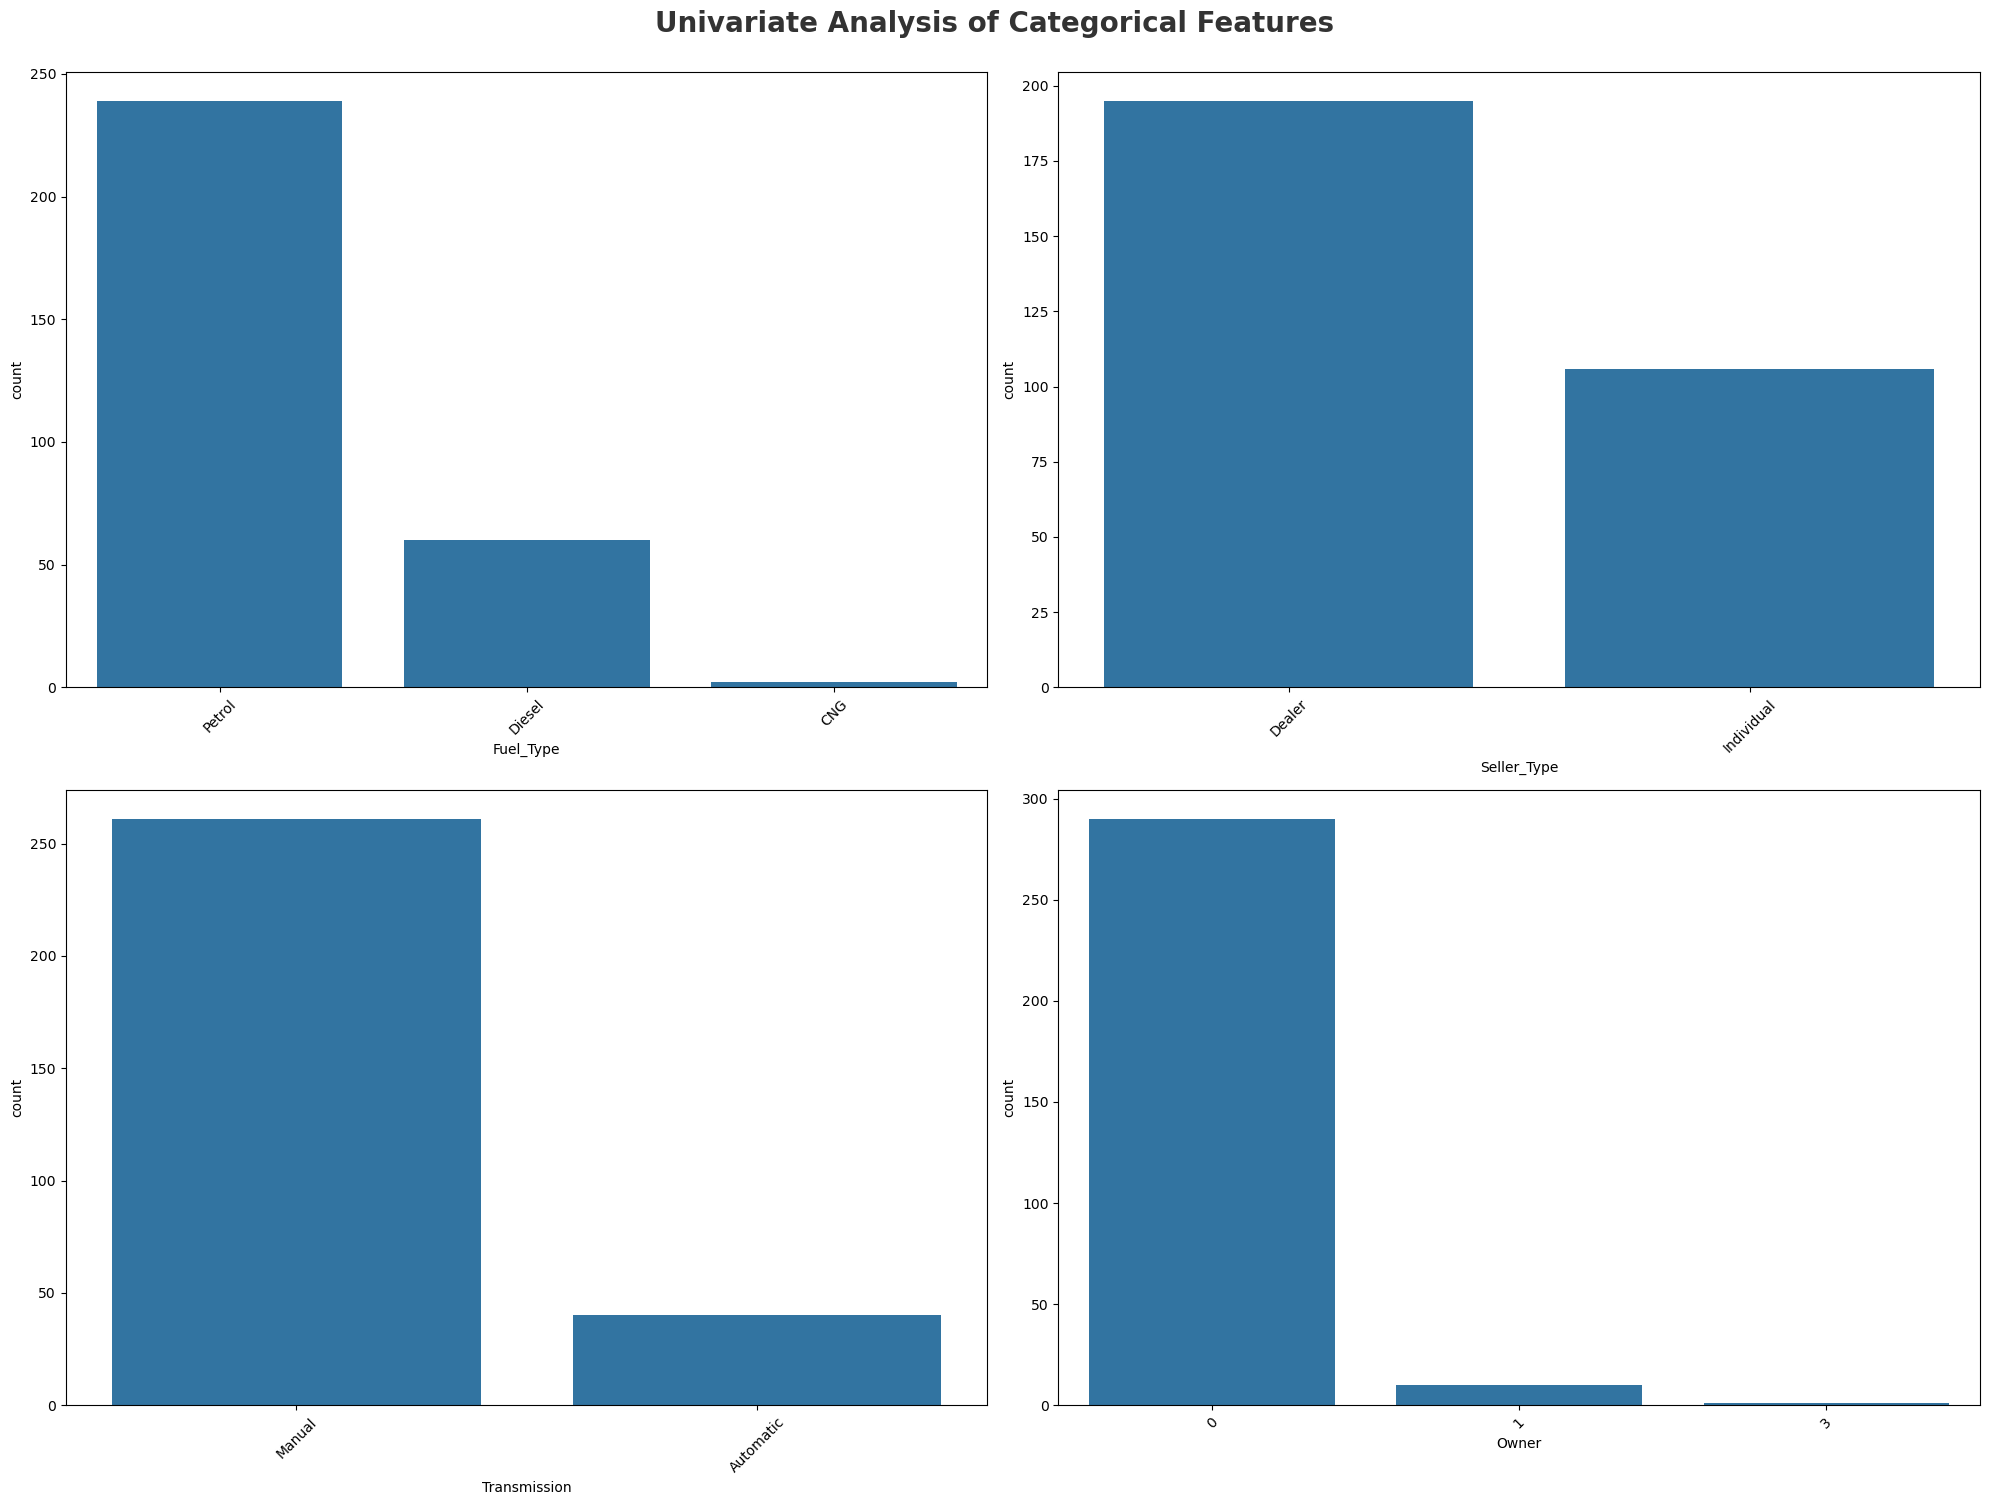

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(20, 15))
plt.suptitle('Univariate Analysis of Categorical Features',
             fontsize=20,
             fontweight='bold',
             alpha=0.8,
             y=1.0)

cat1 = ['Fuel_Type', 'Seller_Type', 'Transmission', 'Owner']

for i in range(len(cat1)):
    plt.subplot(2, 2, i + 1)
    sns.countplot(x=df[cat1[i]])
    plt.xlabel(cat1[i])
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [6]:
numeric_features = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

print(numeric_features)

['Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Owner']


In [7]:
continuous_features = [feature for feature in numeric_features
                       if len(df[feature].unique()) >= 10]

print('Num of continuous features:', continuous_features)

Num of continuous features: ['Year', 'Selling_Price', 'Present_Price', 'Kms_Driven']


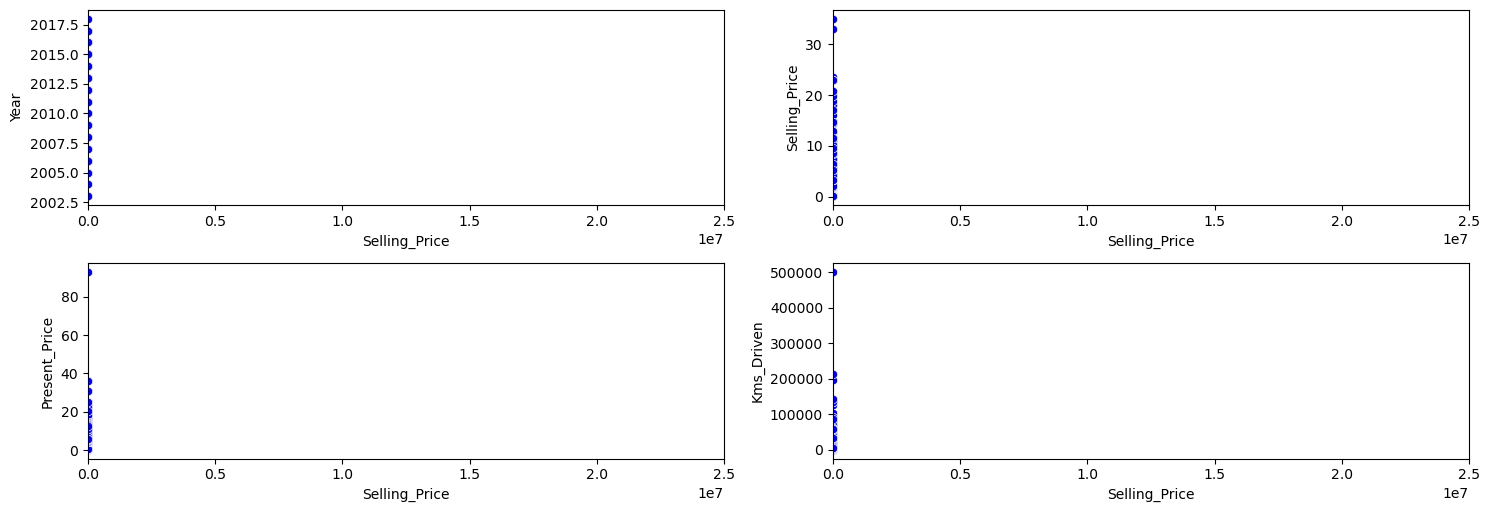

In [9]:
fig = plt.figure(figsize=(15, 20))

for i in range(0, len(continuous_features)):
    ax = plt.subplot(8, 2, i+1)
    sns.scatterplot(data=df, x='Selling_Price', y=continuous_features[i], color='b')
    plt.xlim(0,25000000) # Limit to 25 lakhs Rupees to view clean
    plt.tight_layout()

In [10]:
df [numeric_features].corr()

,Year,Selling_Price,Present_Price,Kms_Driven,Owner
Year,1.000000,0.236141,-0.047584,-0.524342,-0.182104
Selling_Price,0.236141,1.000000,0.878983,0.029187,-0.088344
Present_Price,-0.047584,0.878983,1.000000,0.203647,0.008057
Kms_Driven,-0.524342,0.029187,0.203647,1.000000,0.089216
Owner,-0.182104,-0.088344,0.008057,0.089216,1.000000


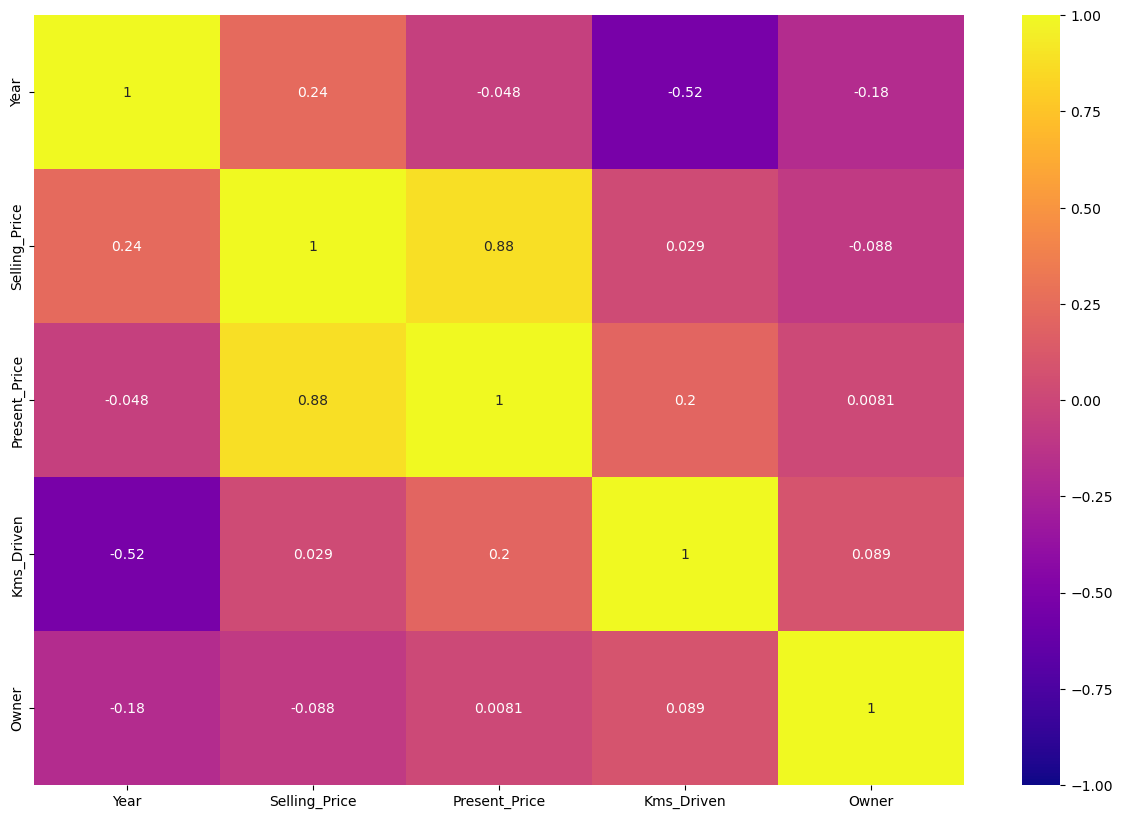

In [12]:
plt.figure(figsize=(15,10))
sns. heatmap(data = df [numeric_features]. corr(), annot= True, cmap= 'plasma', vmin= -1 , vmax= 1, linecolor='white')
plt.show()

In [16]:
from scipy.stats import chi2_contingency
import pandas as pd

categorical_features = df.select_dtypes(include=['object']).columns.tolist()

# Convert Selling_Price into categories
df['Price_Category'] = pd.qcut(
    df['Selling_Price'],
    q=3,
    labels=['Low', 'Medium', 'High']
)

chi2_test = []

for feature in categorical_features:
    p_value = chi2_contingency(
        pd.crosstab(df['Price_Category'], df[feature])
    )[1]

    if p_value < 0.05:
        chi2_test.append('Reject Null Hypothesis')
    else:
        chi2_test.append('Fail to Reject Null Hypothesis')

test_result = pd.DataFrame({
    'Categorical Features': categorical_features,
    'Hypothesis Result': chi2_test
})

print('-'*100)
print('Chi-Square Test Results')
print('-'*100)

print(test_result)

----------------------------------------------------------------------------------------------------
Chi-Square Test Results
----------------------------------------------------------------------------------------------------
  Categorical Features       Hypothesis Result
0             Car_Name  Reject Null Hypothesis
1            Fuel_Type  Reject Null Hypothesis
2          Seller_Type  Reject Null Hypothesis
3         Transmission  Reject Null Hypothesis


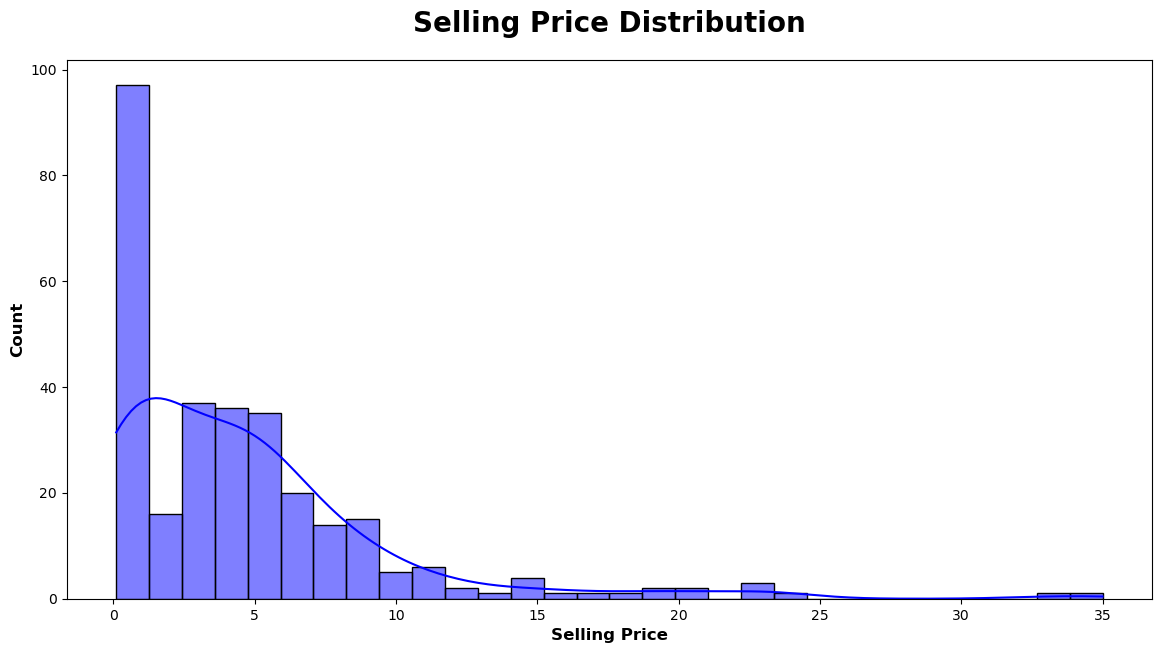

In [20]:
plt.subplots(figsize=(14,7))

sns.histplot(
    df['Selling_Price'],
    bins=30,
    kde=True,
    color='b'
)

plt.title("Selling Price Distribution", weight="bold", fontsize=20, pad=20)
plt.ylabel("Count", weight="bold", fontsize=12)
plt.xlabel("Selling Price", weight="bold", fontsize=12)

plt.show()

In [22]:
print('-'*50)
print('Top 10 Sold Cars on CarDekho Website')
print('-'*50)

print(df['Car_Name'].value_counts().head(10))

--------------------------------------------------
Top 10 Sold Cars on CarDekho Website
--------------------------------------------------
Car_Name
city             26
corolla altis    16
verna            14
fortuner         11
brio             10
ciaz              9
innova            9
i20               9
grand i10         8
jazz              7
Name: count, dtype: int64


In [27]:
import warnings
warnings.filterwarnings('ignore')

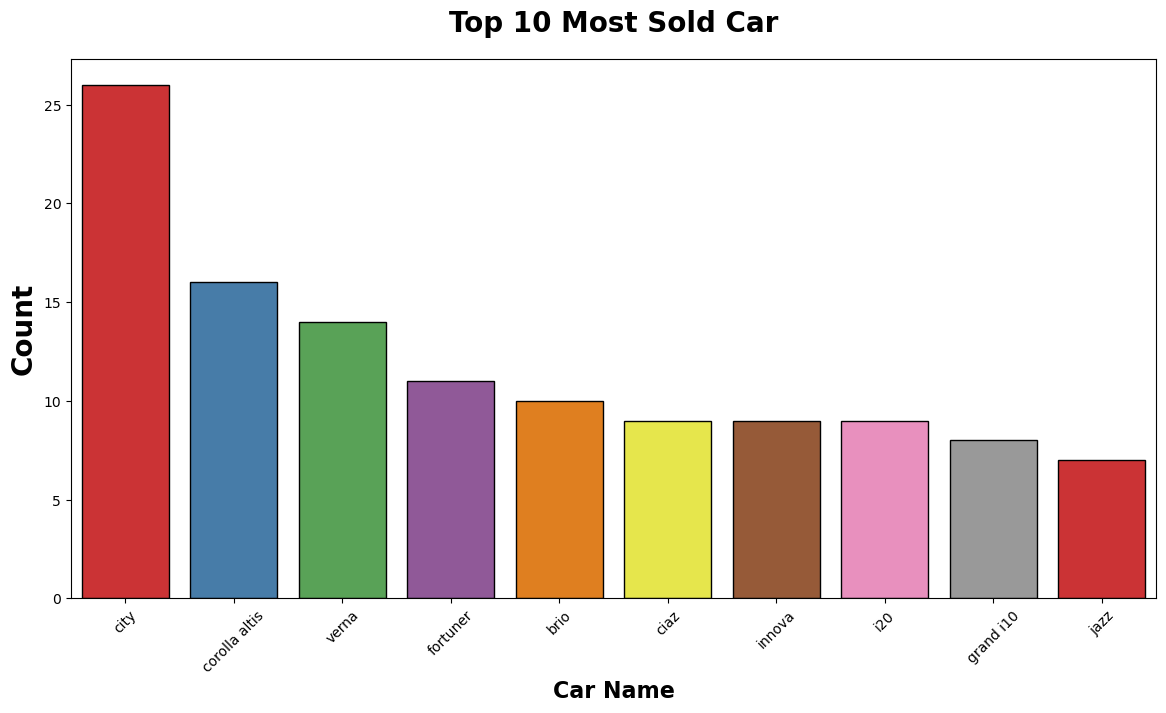

In [28]:
plt.subplots(figsize=(14,7))

sns.countplot(
    x="Car_Name",
    data=df,
    ec="black",
    palette="Set1",
    order=df['Car_Name'].value_counts().index[:10]
)

plt.title("Top 10 Most Sold Car", weight="bold", fontsize=20, pad=20)
plt.ylabel("Count", weight="bold", fontsize=20)
plt.xlabel("Car Name", weight="bold", fontsize=16)
plt.xticks(rotation=45)

plt.show()


In [31]:
# Check available car names containing "i20"
print("Available i20 variants:")
print(df[df['Car_Name'].str.contains('i20', case=False, na=False)]['Car_Name'].unique())

# Calculate mean selling price of i20
i20 = df[df['Car_Name'].str.contains('i20', case=False, na=False)]['Selling_Price'].mean()

print(f"\nThe mean selling price of Hyundai i20 is {i20:.2f} lakhs")

Available i20 variants:
['i20']

The mean selling price of Hyundai i20 is 4.77 lakhs


In [33]:
df['Brand'] = df['Car_Name'].str.split().str[0]

print('-'*50)
print('Top 10 Most Sold Car Brand')
print('-'*50)

df['Brand'].value_counts().head(10)

--------------------------------------------------
Top 10 Most Sold Car Brand
--------------------------------------------------


Brand
city        26
Bajaj       25
Royal       17
corolla     17
Honda       17
Hero        15
verna       14
etios       11
fortuner    11
brio        10
Name: count, dtype: int64

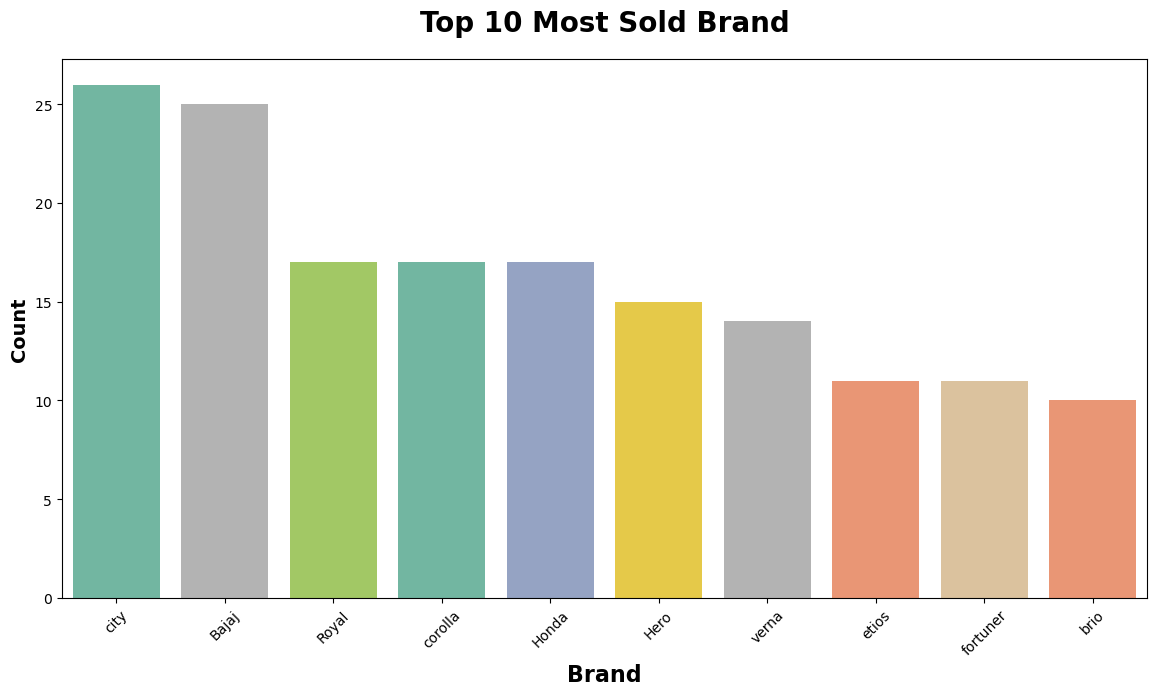

In [34]:
# Create Brand column if it doesn't exist
df['Brand'] = df['Car_Name'].str.split().str[0]

plt.figure(figsize=(14,7))

sns.countplot(
    x='Brand',
    data=df,
    order=df['Brand'].value_counts().head(10).index,
    hue='Brand',
    palette='Set2',
    legend=False
)

plt.title("Top 10 Most Sold Brand", weight="bold", fontsize=20, pad=20)
plt.ylabel("Count", weight="bold", fontsize=14)
plt.xlabel("Brand", weight="bold", fontsize=16)
plt.xticks(rotation=45)

plt.show()

In [35]:
maruti = df[df['Brand'] == 'Maruti']['Selling_Price'].mean()

print(f'The mean price of Maruti is {maruti:.2f} lakhs')

The mean price of Maruti is nan lakhs


In [37]:
# Create Brand column if not already created
df['Brand'] = df['Car_Name'].str.split().str[0]

brand = df.groupby('Brand')['Selling_Price'].max()

brand = brand.to_frame().sort_values(
    'Selling_Price',
    ascending=False
).head(10)

print('-'*50)
print('Top 10 Costliest Brands on CarDekho Website')
print('-'*50)

print(brand)

--------------------------------------------------
Top 10 Costliest Brands on CarDekho Website
--------------------------------------------------
          Selling_Price
Brand                  
land              35.00
fortuner          33.00
innova            23.00
corolla           17.00
creta             12.90
elantra           11.75
city              11.50
vitara             9.25
verna              9.25
ciaz               8.75


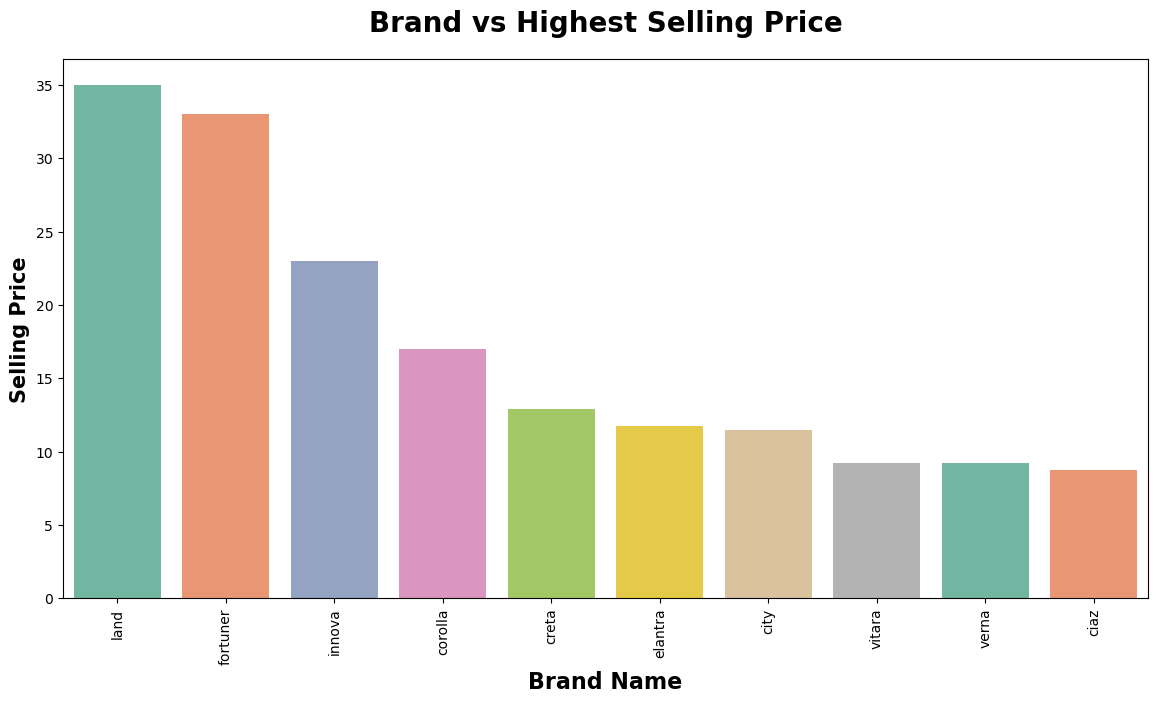

In [38]:
plt.figure(figsize=(14,7))

sns.barplot(
    x=brand.index,
    y=brand['Selling_Price'],
    palette="Set2"
)

plt.title("Brand vs Highest Selling Price", weight="bold", fontsize=20, pad=20)
plt.ylabel("Selling Price", weight="bold", fontsize=15)
plt.xlabel("Brand Name", weight="bold", fontsize=16)
plt.xticks(rotation=90)

plt.show()

In [39]:
car = df.groupby('Car_Name')['Selling_Price'].max()

car = car.to_frame().sort_values(
    'Selling_Price',
    ascending=False
).head(10)

print('-'*50)
print('Top 10 Costliest Cars on CarDekho Website')
print('-'*50)

print(car)

--------------------------------------------------
Top 10 Costliest Cars on CarDekho Website
--------------------------------------------------
               Selling_Price
Car_Name                    
land cruiser           35.00
fortuner               33.00
innova                 23.00
corolla altis          17.00
creta                  12.90
elantra                11.75
city                   11.50
vitara brezza           9.25
verna                   9.25
ciaz                    8.75


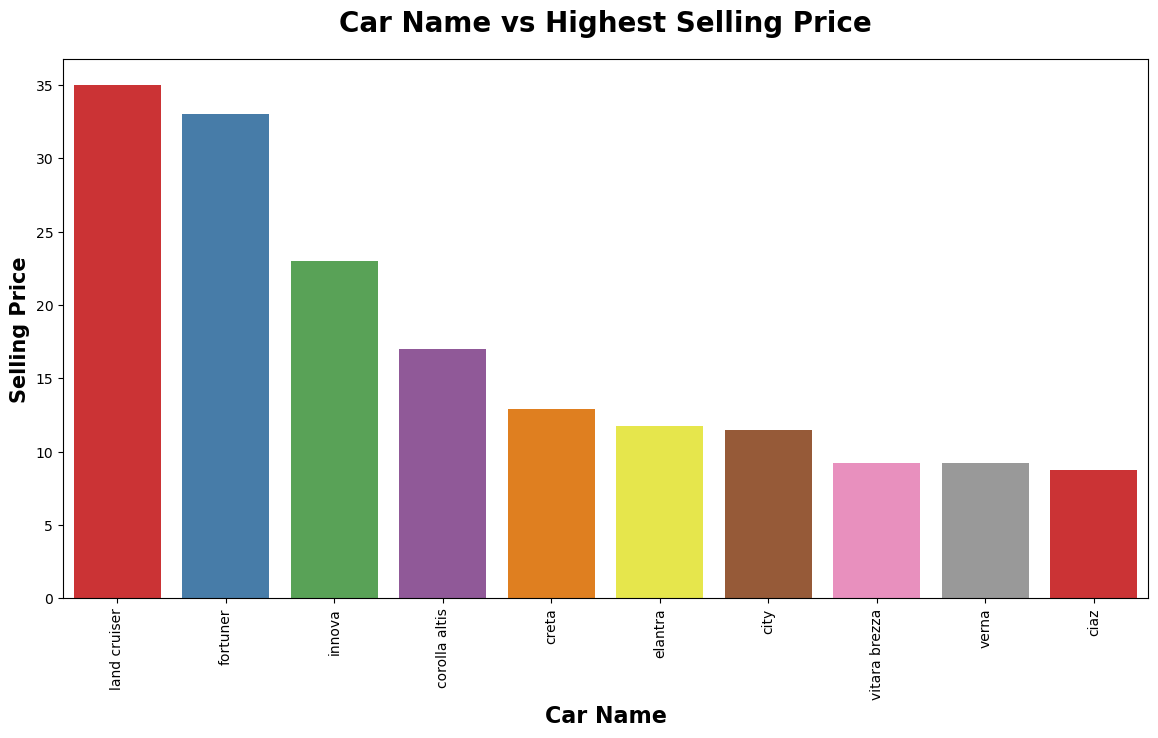

In [41]:
plt.figure(figsize=(14,7))

sns.barplot(
    x=car.index,
    y=car['Selling_Price'],
    palette="Set1"
)

plt.title("Car Name vs Highest Selling Price", weight="bold", fontsize=20, pad=20)
plt.ylabel("Selling Price", weight="bold", fontsize=15)
plt.xlabel("Car Name", weight="bold", fontsize=16)
plt.xticks(rotation=90)

plt.show()

In [42]:
fuel_price = df.groupby('Fuel_Type')['Selling_Price'].mean().sort_values(ascending=False)

print('-'*50)
print('Average Selling Price by Fuel Type')
print('-'*50)

print(fuel_price.to_frame())

--------------------------------------------------
Average Selling Price by Fuel Type
--------------------------------------------------
           Selling_Price
Fuel_Type               
Diesel         10.278500
Petrol          3.264184
CNG             3.100000


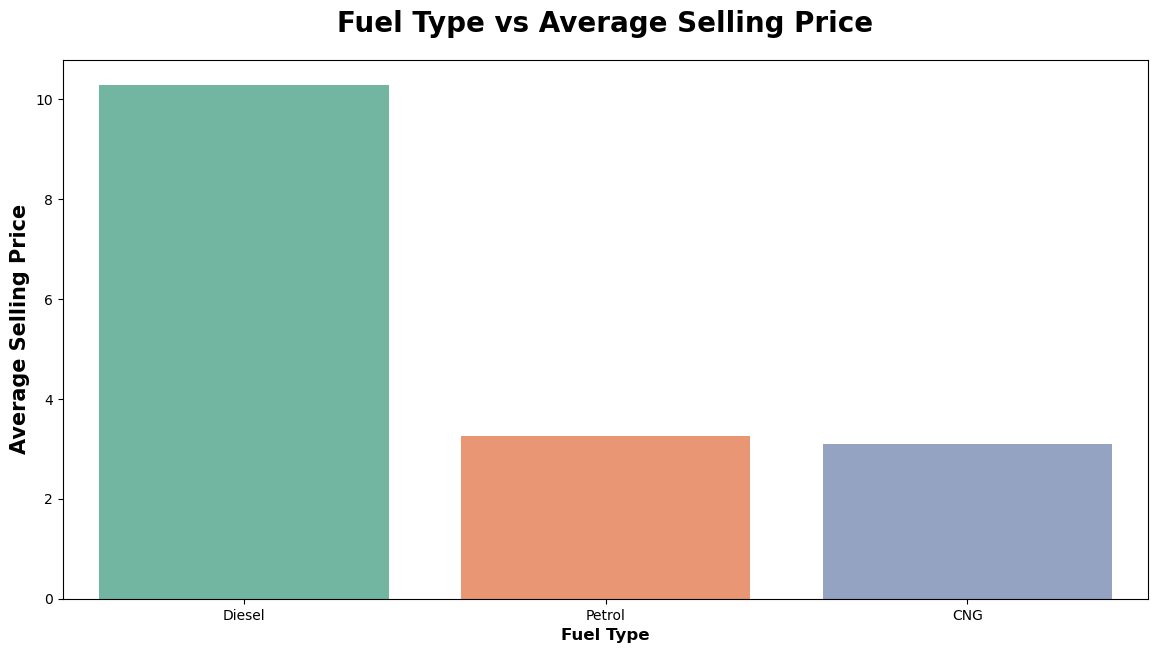

In [44]:
plt.figure(figsize=(14,7))

sns.barplot(
    x=fuel_price.index,
    y=fuel_price.values,
    palette="Set2"
)

plt.title("Fuel Type vs Average Selling Price", weight="bold", fontsize=20, pad=20)
plt.ylabel("Average Selling Price", weight="bold", fontsize=15)
plt.xlabel("Fuel Type", weight="bold", fontsize=12)

plt.show()

In [46]:
car_price = df.groupby('Car_Name')['Selling_Price'].mean() \
              .sort_values(ascending=False) \
              .head(10)

print('-'*50)
print('Top 10 Cars by Average Selling Price')
print('-'*50)

print(car_price.to_frame())

--------------------------------------------------
Top 10 Cars by Average Selling Price
--------------------------------------------------
               Selling_Price
Car_Name                    
land cruiser       35.000000
fortuner           18.685455
innova             12.777778
creta              11.800000
elantra            11.600000
vitara brezza       9.250000
ciaz                7.472222
city                7.419231
corolla altis       7.183125
ertiga              6.775000


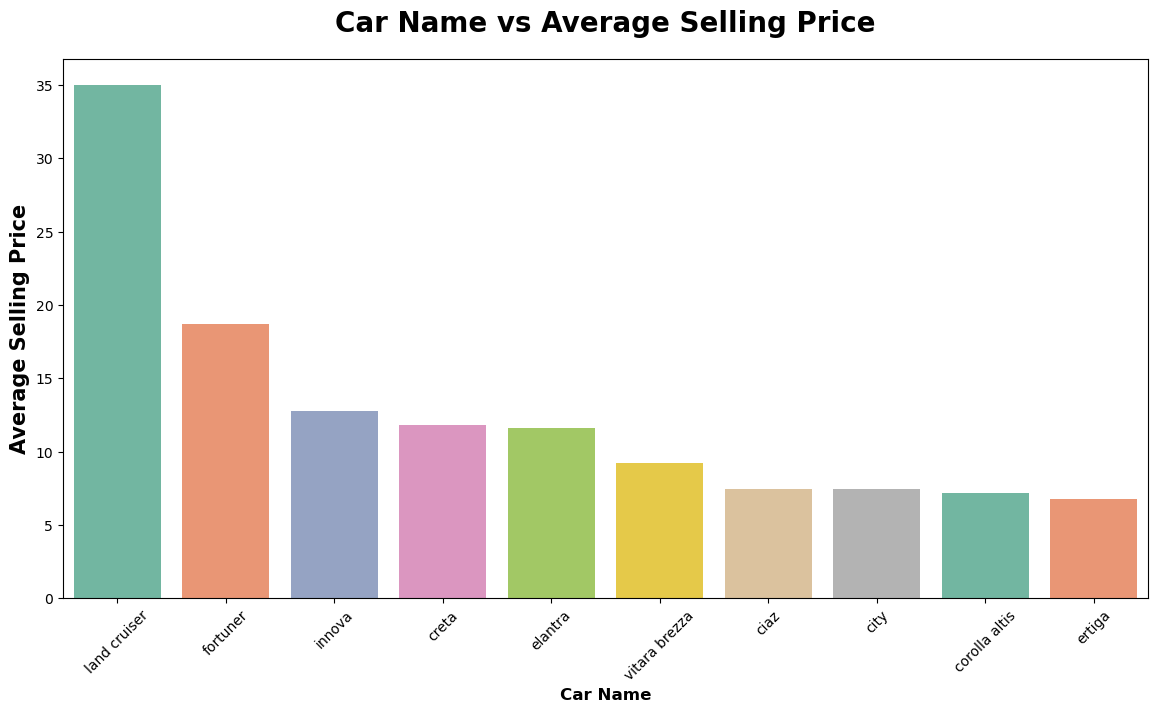

In [47]:
plt.figure(figsize=(14,7))

sns.barplot(
    x=car_price.index,
    y=car_price.values,
    palette='Set2'
)

plt.title("Car Name vs Average Selling Price",
          weight="bold",
          fontsize=20,
          pad=20)

plt.ylabel("Average Selling Price", weight="bold", fontsize=15)
plt.xlabel("Car Name", weight="bold", fontsize=12)

plt.xticks(rotation=45)
plt.show()

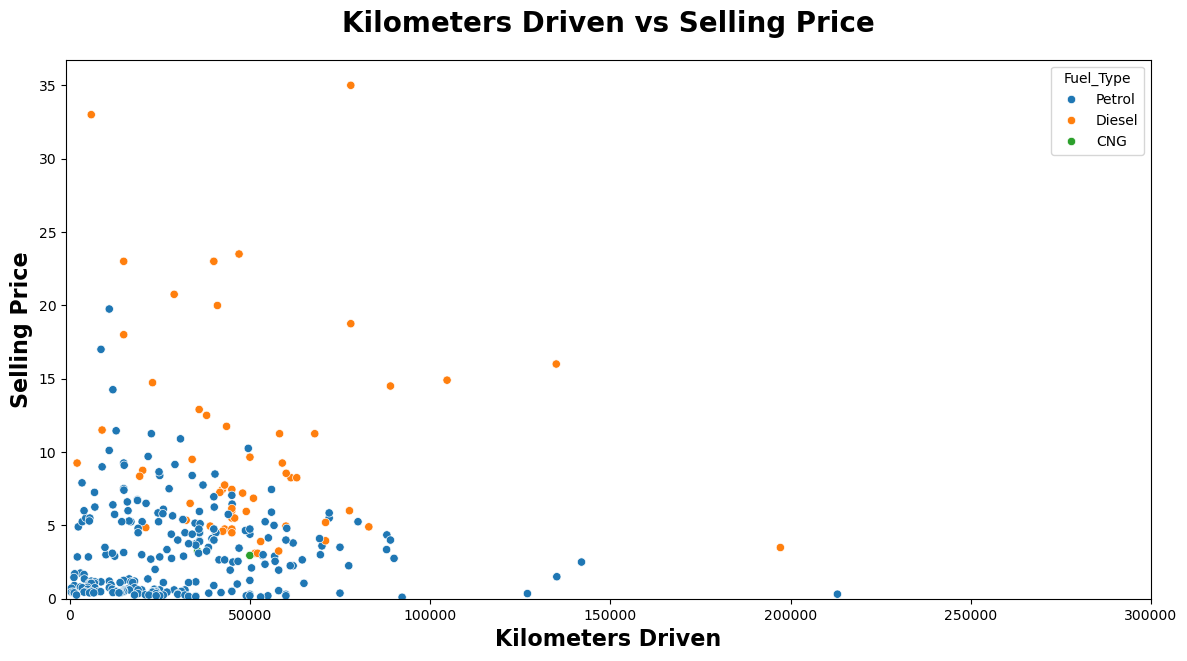

In [48]:
plt.figure(figsize=(14,7))

sns.scatterplot(
    x='Kms_Driven',
    y='Selling_Price',
    data=df,
    color='b',
    hue='Fuel_Type'
)

plt.title("Kilometers Driven vs Selling Price",
          weight="bold",
          fontsize=20,
          pad=20)

plt.ylabel("Selling Price", weight="bold", fontsize=16)
plt.xlabel("Kilometers Driven", weight="bold", fontsize=16)

plt.xlim(-1000, 300000)   # adjusted for this dataset
plt.ylim(bottom=0)

plt.show()

In [50]:
fuel = df.groupby('Fuel_Type')['Selling_Price'].median().sort_values(ascending=False)

fuel.to_frame()

,Selling_Price
Fuel_Type,
Diesel,7.75
CNG,3.10
Petrol,2.65


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)

# Load dataset
url = "https://raw.githubusercontent.com/ayush700714/Car_Price_Prediction_Cardekho_Dataset/master/car%20data.csv"
df = pd.read_csv(url)

print(df.shape)
print(df.columns)

(301, 9)
Index(['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven',
       'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner'],
      dtype='object')


C:\Users\HP\AppData\Local\Temp\ipykernel_41380\694443176.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


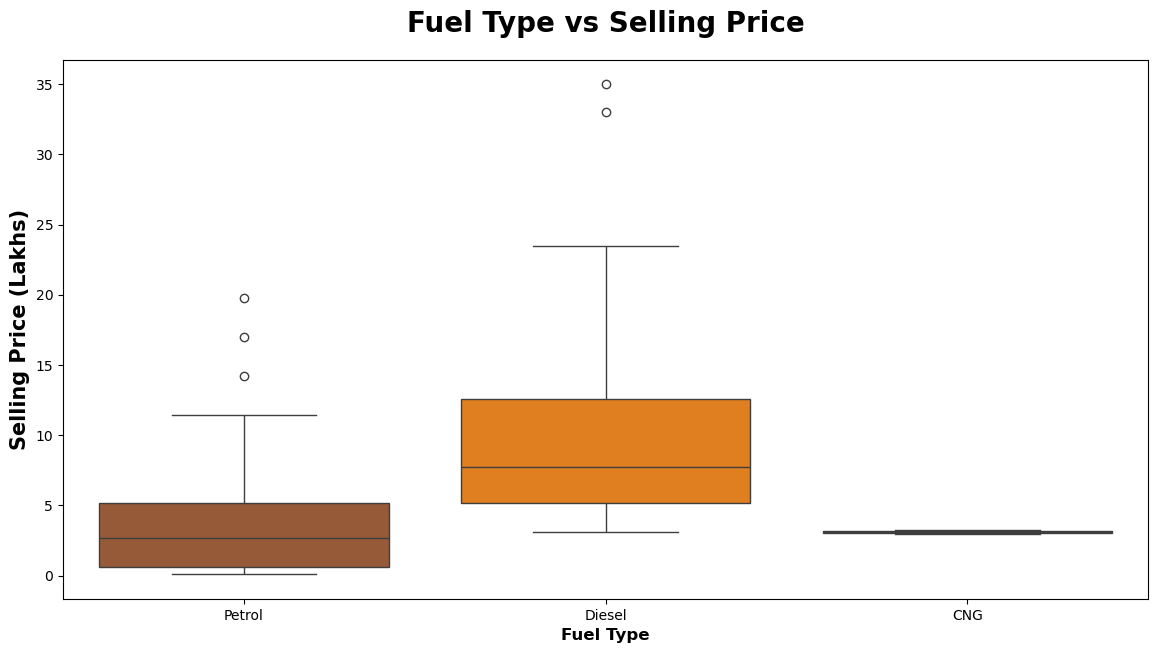

In [4]:
plt.figure(figsize=(14,7))

sns.boxplot(
    x='Fuel_Type',
    y='Selling_Price',
    data=df,
    palette='Set1_r'
)

plt.title("Fuel Type vs Selling Price", weight="bold", fontsize=20, pad=20)
plt.ylabel("Selling Price (Lakhs)", weight="bold", fontsize=15)
plt.xlabel("Fuel Type", weight="bold", fontsize=12)

plt.show()

In [51]:
fuel_kms = df.groupby('Fuel_Type')['Kms_Driven'].mean().sort_values(ascending=False)

print('-'*50)
print('Fuel Type vs Average Kilometers Driven')
print('-'*50)

fuel_kms.to_frame()

--------------------------------------------------
Fuel Type vs Average Kilometers Driven
--------------------------------------------------


,Kms_Driven
Fuel_Type,
Diesel,50369.916667
CNG,42749.000000
Petrol,33528.937238


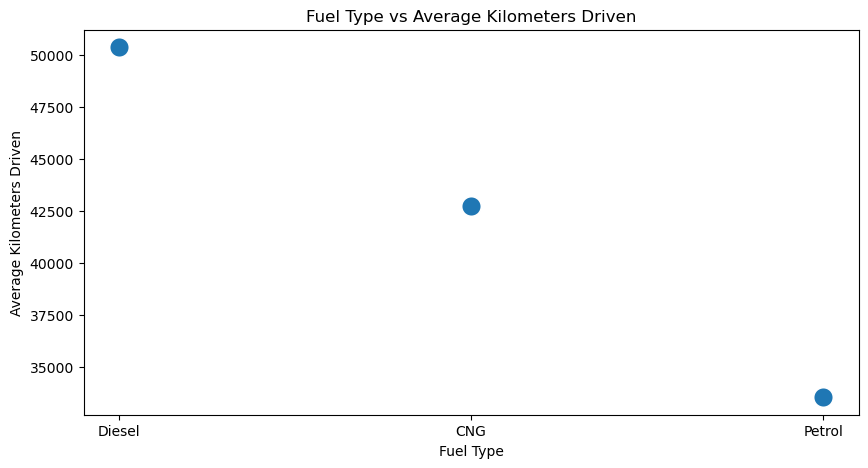

In [54]:
# Create fuel_kms if not already created
fuel_kms = df.groupby('Fuel_Type')['Kms_Driven'].mean().sort_values(ascending=False)

plt.figure(figsize=(10,5))

sns.scatterplot(
    x=fuel_kms.index,
    y=fuel_kms.values,
    s=200
)

plt.title("Fuel Type vs Average Kilometers Driven")
plt.xlabel("Fuel Type")
plt.ylabel("Average Kilometers Driven")

plt.show()

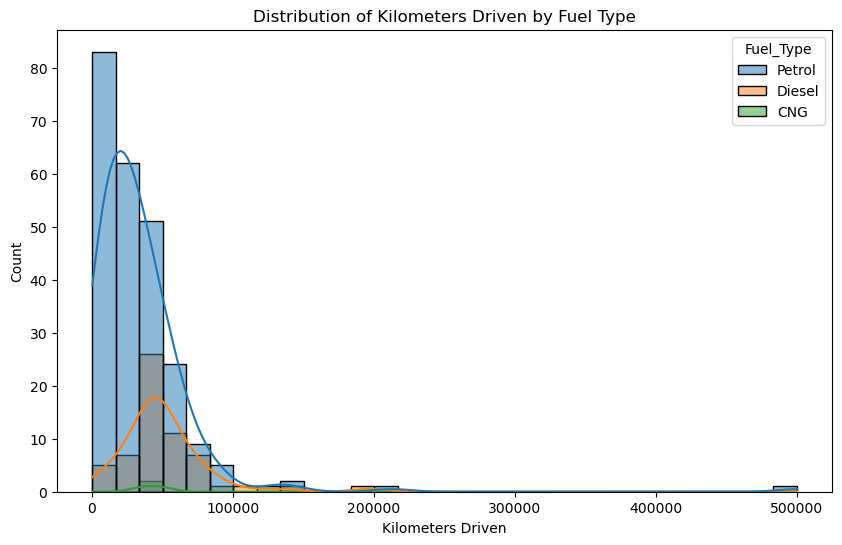

In [56]:
plt.figure(figsize=(10,6))

sns.histplot(
    data=df,
    x='Kms_Driven',
    hue='Fuel_Type',
    kde=True,
    bins=30
)

plt.title("Distribution of Kilometers Driven by Fuel Type")
plt.xlabel("Kilometers Driven")
plt.ylabel("Count")

plt.show()

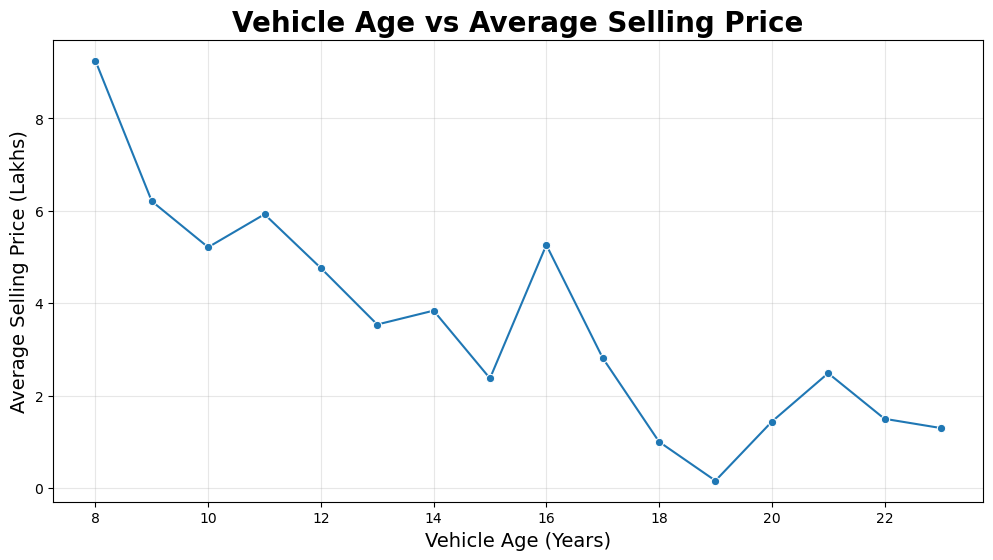

In [57]:
# Create Vehicle Age
df['Vehicle_Age'] = 2026 - df['Year']

# Average selling price by vehicle age
age_price = df.groupby('Vehicle_Age')['Selling_Price'].mean().reset_index()

plt.figure(figsize=(12,6))

sns.lineplot(
    data=age_price,
    x='Vehicle_Age',
    y='Selling_Price',
    marker='o'
)

plt.title('Vehicle Age vs Average Selling Price', fontsize=20, weight='bold')
plt.xlabel('Vehicle Age (Years)', fontsize=14)
plt.ylabel('Average Selling Price (Lakhs)', fontsize=14)

plt.grid(True, alpha=0.3)
plt.show()

In [5]:
# Create Vehicle Age
df['Vehicle_Age'] = 2026 - df['Year']

# Median selling price by vehicle age
vehicle_age = df.groupby('Vehicle_Age')['Selling_Price'].median().sort_values(ascending=False)

print('-'*50)
print('Vehicle Age vs Median Selling Price')
print('-'*50)

vehicle_age.to_frame().head(10)

--------------------------------------------------
Vehicle Age vs Median Selling Price
--------------------------------------------------


,Selling_Price
Vehicle_Age,
8,9.250
10,5.250
11,5.250
12,4.450
9,3.500
13,3.500
17,3.175
21,3.120
14,3.100


C:\Users\HP\AppData\Local\Temp\ipykernel_41380\2368875185.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


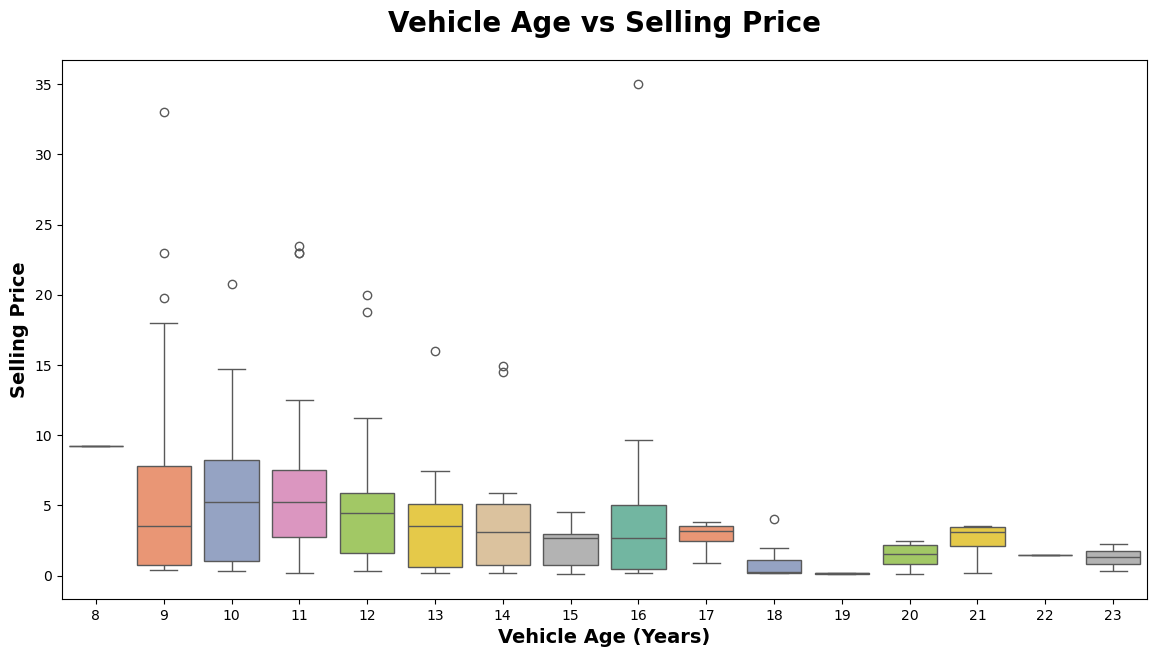

In [6]:
# Create Vehicle Age if not already created
df['Vehicle_Age'] = 2026 - df['Year']

plt.figure(figsize=(14,7))

sns.boxplot(
    x='Vehicle_Age',
    y='Selling_Price',
    data=df,
    palette='Set2'
)

plt.title("Vehicle Age vs Selling Price", weight="bold", fontsize=20, pad=20)
plt.xlabel("Vehicle Age (Years)", weight="bold", fontsize=14)
plt.ylabel("Selling Price", weight="bold", fontsize=14)

plt.show()

In [8]:
# Create Vehicle Age if not already created
df['Vehicle_Age'] = 2026 - df['Year']

oldest = df.groupby('Car_Name')['Vehicle_Age'] \
           .max() \
           .sort_values(ascending=False) \
           .head(10)

print('-'*50)
print('Top 10 Oldest Cars')
print('-'*50)

oldest.to_frame()

--------------------------------------------------
Top 10 Oldest Cars
--------------------------------------------------


,Vehicle_Age
Car_Name,
800,23
sx4,23
corolla,22
Hero Super Splendor,21
innova,21
wagon r,20
camry,20
city,20
Bajaj Pulsar 150,20


C:\Users\HP\AppData\Local\Temp\ipykernel_41380\2396090588.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


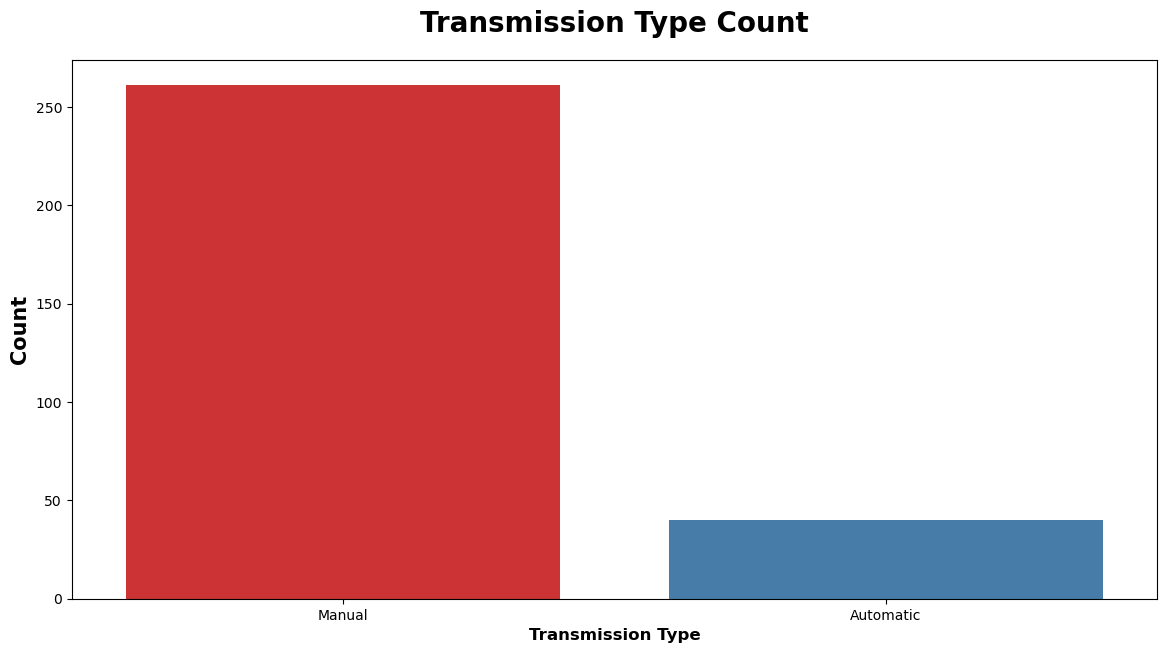

In [9]:
plt.figure(figsize=(14,7))

sns.countplot(
    x='Transmission',
    data=df,
    palette='Set1'
)

plt.title("Transmission Type Count", weight="bold", fontsize=20, pad=20)
plt.ylabel("Count", weight="bold", fontsize=15)
plt.xlabel("Transmission Type", weight="bold", fontsize=12)

plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_41380\2355216322.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


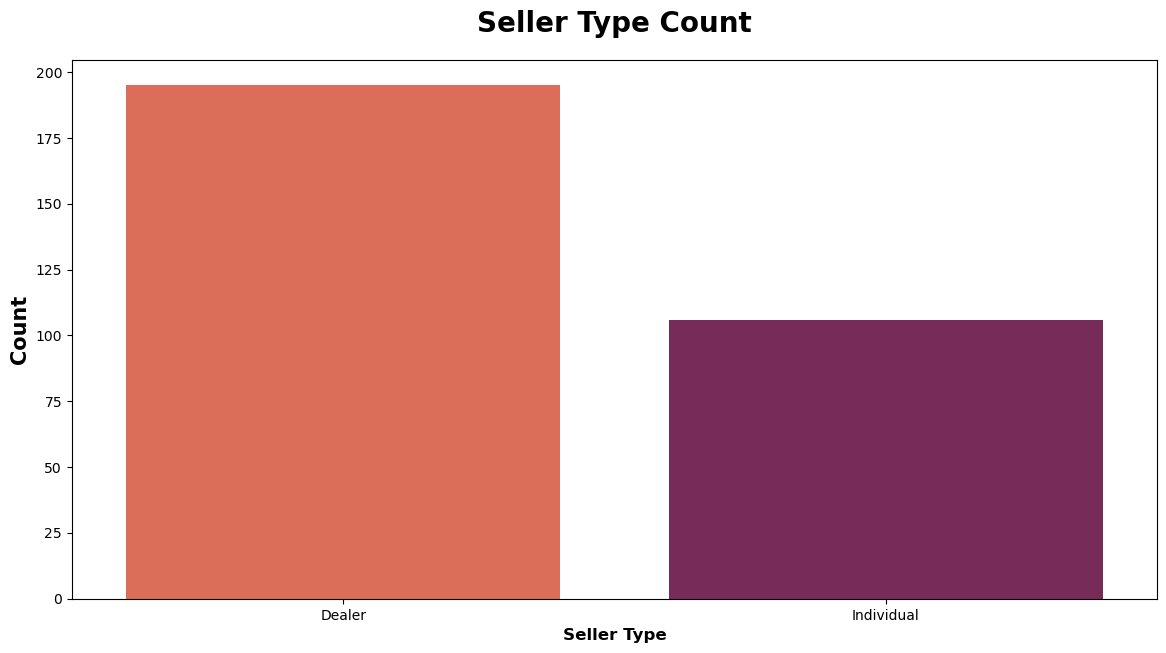

In [10]:
plt.figure(figsize=(14,7))

sns.countplot(
    x='Seller_Type',
    data=df,
    palette='rocket_r'
)

plt.title("Seller Type Count", weight="bold", fontsize=20, pad=20)
plt.ylabel("Count", weight="bold", fontsize=15)
plt.xlabel("Seller Type", weight="bold", fontsize=12)

plt.show()

In [11]:
dealer = df.groupby('Seller_Type')['Selling_Price'] \
           .median() \
           .sort_values(ascending=False)

dealer.to_frame()

,Selling_Price
Seller_Type,
Dealer,5.250
Individual,0.515


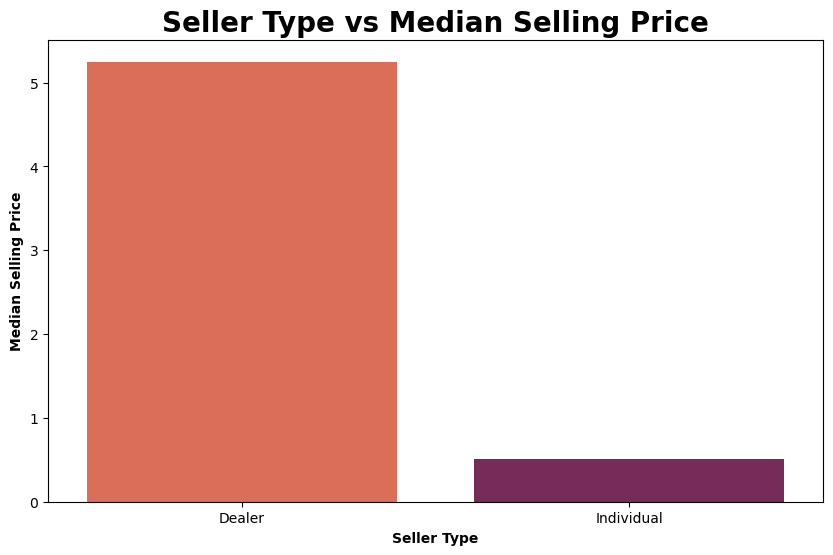

In [12]:
plt.figure(figsize=(10,6))

sns.barplot(
    x=dealer.index,
    y=dealer.values,
    hue=dealer.index,
    palette='rocket_r',
    legend=False
)

plt.title("Seller Type vs Median Selling Price", weight="bold", fontsize=20)
plt.xlabel("Seller Type", weight="bold")
plt.ylabel("Median Selling Price", weight="bold")

plt.show()

In [13]:
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Vehicle_Age
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0,12
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0,13
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0,9
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0,15
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0,12


In [14]:
df_model=df.copy()

df_model

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Vehicle_Age
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0,12
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0,13
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0,9
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0,15
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0,12
...,...,...,...,...,...,...,...,...,...,...
296,city,2016,9.50,11.60,33988,Diesel,Dealer,Manual,0,10
297,brio,2015,4.00,5.90,60000,Petrol,Dealer,Manual,0,11
298,city,2009,3.35,11.00,87934,Petrol,Dealer,Manual,0,17
299,city,2017,11.50,12.50,9000,Diesel,Dealer,Manual,0,9


In [16]:
df_model.head()
print(df_model.columns)

Index(['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven',
       'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner', 'Vehicle_Age'],
      dtype='object')


In [19]:
print(df_model.columns.tolist())

['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner', 'Vehicle_Age']


In [20]:
df_model.drop(columns=['Car_Name', 'Year'], inplace=True)

df_model

,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Vehicle_Age
0,3.35,5.59,27000,Petrol,Dealer,Manual,0,12
1,4.75,9.54,43000,Diesel,Dealer,Manual,0,13
2,7.25,9.85,6900,Petrol,Dealer,Manual,0,9
3,2.85,4.15,5200,Petrol,Dealer,Manual,0,15
4,4.60,6.87,42450,Diesel,Dealer,Manual,0,12
...,...,...,...,...,...,...,...,...
296,9.50,11.60,33988,Diesel,Dealer,Manual,0,10
297,4.00,5.90,60000,Petrol,Dealer,Manual,0,11
298,3.35,11.00,87934,Petrol,Dealer,Manual,0,17
299,11.50,12.50,9000,Diesel,Dealer,Manual,0,9


In [21]:
df_model=pd.get_dummies(df_model,dtype=float)
df_model

,Selling_Price,Present_Price,Kms_Driven,Owner,Vehicle_Age,Fuel_Type_CNG,Fuel_Type_Diesel,Fuel_Type_Petrol,Seller_Type_Dealer,Seller_Type_Individual,Transmission_Automatic,Transmission_Manual
0,3.35,5.59,27000,0,12,0.0,0.0,1.0,1.0,0.0,0.0,1.0
1,4.75,9.54,43000,0,13,0.0,1.0,0.0,1.0,0.0,0.0,1.0
2,7.25,9.85,6900,0,9,0.0,0.0,1.0,1.0,0.0,0.0,1.0
3,2.85,4.15,5200,0,15,0.0,0.0,1.0,1.0,0.0,0.0,1.0
4,4.60,6.87,42450,0,12,0.0,1.0,0.0,1.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...
296,9.50,11.60,33988,0,10,0.0,1.0,0.0,1.0,0.0,0.0,1.0
297,4.00,5.90,60000,0,11,0.0,0.0,1.0,1.0,0.0,0.0,1.0
298,3.35,11.00,87934,0,17,0.0,0.0,1.0,1.0,0.0,0.0,1.0
299,11.50,12.50,9000,0,9,0.0,1.0,0.0,1.0,0.0,0.0,1.0


In [22]:
df_model.dtypes

Selling_Price             float64
Present_Price             float64
Kms_Driven                  int64
Owner                       int64
Vehicle_Age                 int64
Fuel_Type_CNG             float64
Fuel_Type_Diesel          float64
Fuel_Type_Petrol          float64
Seller_Type_Dealer        float64
Seller_Type_Individual    float64
Transmission_Automatic    float64
Transmission_Manual       float64
dtype: object

In [23]:
X=df_model.drop('selling_price', axis=1)
X

# Feature Matrix

KeyError: "['selling_price'] not found in axis"